In [ ]:
#| default_exp player

# A player

> Play, pause at a word, seek, skip, change speed and change voice, one control at a time.

We have a voice that says where every word is (notebook 100) and a speed-up that can change speed mid-stream
(notebook 101). This notebook builds the player on top: the controls audio-reader gives Alex.

The plan. Split the text into sentences. A background thread renders the next few at 1x. The sound card asks for audio
a block at a time with `pull(n)`, which takes 1x audio from the current sentence, passes it through a Sonic stream and
returns sped-up audio. Everything the player knows (where it is, where the words are, where to pause) is in 1x samples;
only Sonic knows the speed. And since `pull` doesn't need a sound card, we can test every control without one.

In [ ]:
#| export
import re
import threading
import time
import warnings
from dataclasses import dataclass

import numpy as np
import sounddevice as sd
import spacy
from fastcore.utils import patch

from text_to_speech.sonic import Sonic
from text_to_speech.voice import SR, Word, analyse, decode, words

In [ ]:
import matplotlib.pyplot as plt
from fastcore.test import test_close, test_eq
from IPython.display import Audio

## Sentences

The unit of rendering is the sentence: small enough that the first one is ready quickly, big enough for Kokoro to
plan its intonation. spaCy, which Kokoro's frontend already loads, finds the boundaries. We split into paragraphs
first so no sentence crosses one, and keep character offsets into the original text: that's what a reading position
is.

In [ ]:
#| export
with warnings.catch_warnings():  # spaCy loads curated-transformers, which we never use, and it warns on 3.14+
    warnings.filterwarnings("ignore", message="`torch.jit.script` is not supported")
    nlp = spacy.load("en_core_web_sm", exclude=["ner", "lemmatizer"])


def sentence_spans(text):
    "(start, end) character offsets of every sentence in `text`. Paragraphs are separated by blank lines."
    spans = []
    for para in re.finditer(r"[^\n]+(?:\n[^\n]+)*", text):
        spans += [(para.start() + s.start_char, para.start() + s.end_char) for s in nlp(para.group()).sents]
    return [(a, b) for a, b in spans if text[a:b].strip()]

In [ ]:
article = """Talking machines are older than computers. In 1939 Homer Dudley's Voder, played like an organ by a trained
operator, spoke at the New York World's Fair. It took a year of practice to make it say anything at all.

Dr. Dennis Klatt's work at MIT in the 1970s and 1980s gave the world rule-based voices that ran on a chip. Stephen
Hawking used one for decades, and kept it after better ones existed, because it had become his voice.

Neural voices arrived in 2016. They sound far more human, but they are large, and for a long time they could not run
on a phone at all. Making one small enough, and controllable enough, is the point of this project."""

spans = sentence_spans(article)
test_eq(article[slice(*spans[3])][:3], "Dr.")  # "Dr." didn't end a sentence
test_eq(len(spans), 8)
spans[:3]

[(0, 42), (43, 152), (153, 211)]

## Rendering a sentence

`render` says one sentence and moves its words into the article's coordinates. Kokoro pads every render with silence,
nearly a second in all, which would sit between every pair of sentences. We know where the first and last words are,
so we cut there, with a margin because the timings are approximate. A line break inside a paragraph is sent as a
space: Kokoro's frontend would otherwise treat the words either side as one. The decoder is an argument, as in
`say`.

In [ ]:
#| export
@dataclass
class Sentence:
    audio: np.ndarray  # float32 at 1x, trimmed to the speech
    words: list  # Words, with positions in the whole text and in `audio`


def render(text, start, end, voice="af_heart", decoder=decode, margin=(0.1, 0.25)):
    "Say `text[start:end]`, trimmed to the speech, with each word's place in `text` and in the audio."
    u = analyse(text[start:end].replace("\n", " "), voice)  # Same length, so offsets still line up
    audio, ws = np.asarray(decoder(u), dtype=np.float32), words(u)
    if not ws:
        return Sentence(audio, [])
    first = max(0, ws[0].sample_start - int(margin[0] * SR))
    last = ws[-1].sample_end + int(margin[1] * SR)
    shift = lambda w: Word(
        w.text, start + w.char_start, start + w.char_end, w.sample_start - first, w.sample_end - first
    )
    return Sentence(audio[first:last], [shift(w) for w in ws])

In [ ]:
s = render(article, *spans[4])
for w in s.words:
    test_eq(article[w.char_start : w.char_end], w.text)
test_eq(s.words[:2], [w for w in s.words if w.text in ("Stephen", "Hawking")])  # Not one word across the line break
print(f"{len(s.audio) / SR:.2f}s:", [w.text for w in s.words])
Audio(s.audio, rate=SR)

6.90s: ['Stephen', 'Hawking', 'used', 'one', 'for', 'decades', 'and', 'kept', 'it', 'after', 'better', 'ones', 'existed', 'because', 'it', 'had', 'become', 'his', 'voice']


## The player's state

A sentence index and a position within it, in 1x samples, make the playhead. A mode says what it's doing: *playing*;
*pausing*, still playing to the end of the current word; *draining*, letting Sonic empty out what it holds; or
*paused*. A lock guards all of it, since the sound card calls from its own thread.

A background thread keeps the current sentence and the next `lookahead` rendered. It renders outside the lock, and
throws a render away if the voice changed while it was working.

In [ ]:
#| export
class Player:
    "Reads `text` aloud. Like audio-reader's ArticlePlayer: play, pause at a word, seek, skip, speed and voice."

    def __init__(self, text, voice="af_heart", speed=1.0, decoder=decode, on_word=None, lookahead=2):
        self.text, self.voice, self.decoder, self.on_word, self.lookahead = text, voice, decoder, on_word, lookahead
        self.spans = sentence_spans(text)
        self.rendered = {}  # Sentence index -> Sentence
        self.index, self.pos = 0, 0  # The playhead: a sentence, and a 1x sample within it
        self.speed, self.sonic = speed, Sonic(speed)
        self.mode, self.stop_at = "paused", 0
        self.lock = threading.Condition()
        threading.Thread(target=self._render_ahead, daemon=True).start()

    def _render_ahead(self):
        while True:
            with self.lock:
                ahead = range(self.index, min(self.index + self.lookahead + 1, len(self.spans)))
                todo = [i for i in ahead if i not in self.rendered]
                if not todo:
                    self.lock.wait()
                    continue
                i, voice = todo[0], self.voice
            sentence = render(self.text, *self.spans[i], voice=voice, decoder=self.decoder)
            with self.lock:
                if voice == self.voice:
                    self.rendered[i] = sentence
                self.lock.notify_all()

    def ready(self):
        "Is the sentence at the playhead rendered?"
        with self.lock:
            return self.index in self.rendered

In [ ]:
player = Player(article)
while not player.ready():
    time.sleep(0.05)
time.sleep(1)
print(f"rendered so far: {sorted(player.rendered)}, mode {player.mode}")

rendered so far: [0], mode paused


## Playing

`pull(n)` is the whole audio path. It reads what Sonic has ready, and when that runs out it calls `_feed` for the next
block of 1x audio, which is also where words are announced, pauses land and sentences advance. If the next sentence
isn't rendered yet it returns silence, because a sound card won't wait.

In [ ]:
#| export
BLOCK = 1024  # 1x samples fed to Sonic at a time


@patch
def pull(self: Player, n):
    "The next `n` samples to play, at the current speed. Silence when paused or still rendering."
    out = np.zeros(n, np.float32)
    with self.lock:
        filled = 0
        while filled < n and self.mode != "paused":
            got = self.sonic.read(out[filled:])
            filled += got
            if filled == n:
                break
            if self.mode == "draining":
                if got == 0:
                    self.mode = "paused"
            elif not self._feed():
                break
    return out


@patch
def _feed(self: Player):
    "Write the next block of 1x audio into Sonic. False if there's nothing to write yet."
    s = self.rendered.get(self.index)
    if s is None:
        return False
    stop = self.stop_at if self.mode == "pausing" else len(s.audio)
    if self.pos >= stop:
        if self.mode == "pausing" or self.index == len(self.spans) - 1:
            self.sonic.flush()
            self.mode = "draining"
        else:
            self.index, self.pos = self.index + 1, 0
            self.lock.notify_all()
        return True
    end = min(self.pos + BLOCK, stop)
    for w in s.words:
        if self.on_word and self.pos <= w.sample_start < end:
            self.on_word(w.char_start, w.char_end)
    self.sonic.write(s.audio[self.pos : end])
    self.pos = end
    return True


@patch
def play(self: Player):
    with self.lock:
        self.mode = "playing"

To test it, we do what a sound card does: call `pull` every 20 ms of output and keep what comes out. `session` also
runs a script of button presses at set times and records the words announced and the player's position. When the
renderer falls behind it waits, so the recording isn't full of gaps; we're testing the controls here, not the
renderer.

In [ ]:
#| export
def session(player, script, seconds, block=480):
    "Pull `seconds` of output, running `script` (time -> function) as the clock passes. Returns audio, words, positions."
    out, heard, positions, pending = [], [], [], sorted(script.items())
    player.on_word = lambda a, b: heard.append((len(out) * block / SR, player.text[a:b]))
    for k in range(int(seconds * SR / block)):
        while pending and pending[0][0] <= k * block / SR:
            pending.pop(0)[1]()
        while player.mode != "paused" and not player.ready():
            time.sleep(0.01)
        out.append(player.pull(block))
        positions.append(player.position() if hasattr(player, "position") else 0)
    return np.concatenate(out), heard, np.array(positions)

At 1x, Sonic passes audio straight through (to within the rounding of the 16-bit audio it works in internally), so
what comes out should be the rendered sentences, word for word:

In [ ]:
player = Player(article)
recording, heard, _ = session(player, {0: player.play}, 4)
first = player.rendered[0].audio
test_close(recording[: len(first)], first, eps=2 / 2**15)
test_eq([w for _, w in heard][:6], ["Talking", "machines", "are", "older", "than", "computers"])
Audio(recording, rate=SR)

## Pausing

Alex pauses at the end of the current word (`pauseSpeaking(at: .word)`), because stopping mid-word sounds like a
fault. We find the word the playhead is in and play on to its end.

In [ ]:
#| export
@patch
def pause(self: Player):
    "Stop at the end of the word being spoken."
    with self.lock:
        if self.mode != "playing":
            return
        s = self.rendered.get(self.index)
        word = next((w for w in s.words if w.sample_end > self.pos), None) if s else None
        self.stop_at = word.sample_end if word and word.sample_start < self.pos else self.pos
        self.mode = "pausing"

In [ ]:
player = Player(article)
recording, heard, _ = session(player, {0: player.play, 2: player.pause, 3: player.play}, 5)
after = recording[2 * SR : 3 * SR]
silent_from = 2 + np.flatnonzero(np.abs(after) > 1e-4).max(initial=0) / SR
print(f"paused at 2.00 s, silent from {silent_from:.2f} s;", [w for t, w in heard if 1.5 < t < 3.5])
assert silent_from < 2.8, "a pause should land at the end of a word"
test_eq(np.abs(recording[int(2.9 * SR) : 3 * SR]).max(), 0)

paused at 2.00 s, silent from 2.49 s; ['than', 'computers', 'In', '1939']


## Where we are, and seeking

The position is in 1x seconds, like audio-reader's media time, so it doesn't move when the speed changes. Sentences
not rendered yet count at an estimated 15 characters a second. A seek lands on the start of the word at that time, so
nothing is skipped; if that sentence isn't rendered yet, on the start of the sentence.

In [ ]:
#| export
CHARS_PER_SECOND = 15  # Kokoro at 1x


@patch
def _duration(self: Player, i):
    s = self.rendered.get(i)
    return len(s.audio) / SR if s else (self.spans[i][1] - self.spans[i][0]) / CHARS_PER_SECOND


@patch
def position(self: Player):
    "Seconds into the text at 1x."
    with self.lock:
        return sum(self._duration(i) for i in range(self.index)) + self.pos / SR


@patch
def seek(self: Player, seconds):
    "Jump to `seconds` at 1x, landing on the start of the word there."
    with self.lock:
        i, t = 0, max(seconds, 0)
        while i < len(self.spans) - 1 and t >= self._duration(i):
            t, i = t - self._duration(i), i + 1
        s, pos = self.rendered.get(i), 0
        if s:
            pos = max([w.sample_start for w in s.words if w.sample_start <= int(t * SR)], default=0)
        self.index, self.pos, self.sonic = i, pos, Sonic(self.speed)
        if self.mode != "paused":
            self.mode = "playing"
        self.lock.notify_all()


@patch
def skip(self: Player, seconds):
    self.seek(self.position() + seconds)

In [ ]:
player = Player(article)
recording, heard, positions = session(player, {0: player.play, 6: lambda: player.skip(-4)}, 8)
times = np.arange(1, len(positions) + 1) * 480 / SR
jump = np.interp(6.05, times, positions) - np.interp(5.95, times, positions)
print(f"skipped {jump:+.2f} s, then:", [w for t, w in heard if 6 <= t < 7])
assert -4.5 < jump < -3.5

skipped -4.18 s, then: ['computers']


## Speed and voice

Speed is Sonic's, so a change takes effect on the next block. A new voice changes the audio and where every word
falls, so it throws away what's rendered and restarts the current sentence.

In [ ]:
#| export
@patch
def set_speed(self: Player, speed):
    with self.lock:
        self.speed = speed
        self.sonic.set_speed(speed)


@patch
def set_voice(self: Player, voice):
    "Switch voice from the start of the current sentence."
    with self.lock:
        self.voice, self.rendered = voice, {}
        self.pos, self.sonic = 0, Sonic(self.speed)
        if self.mode != "paused":
            self.mode = "playing"
        self.lock.notify_all()

Now everything at once. The position should climb at 1x, stop for the pause, climb twice and three times as fast, and jump back at the skip:

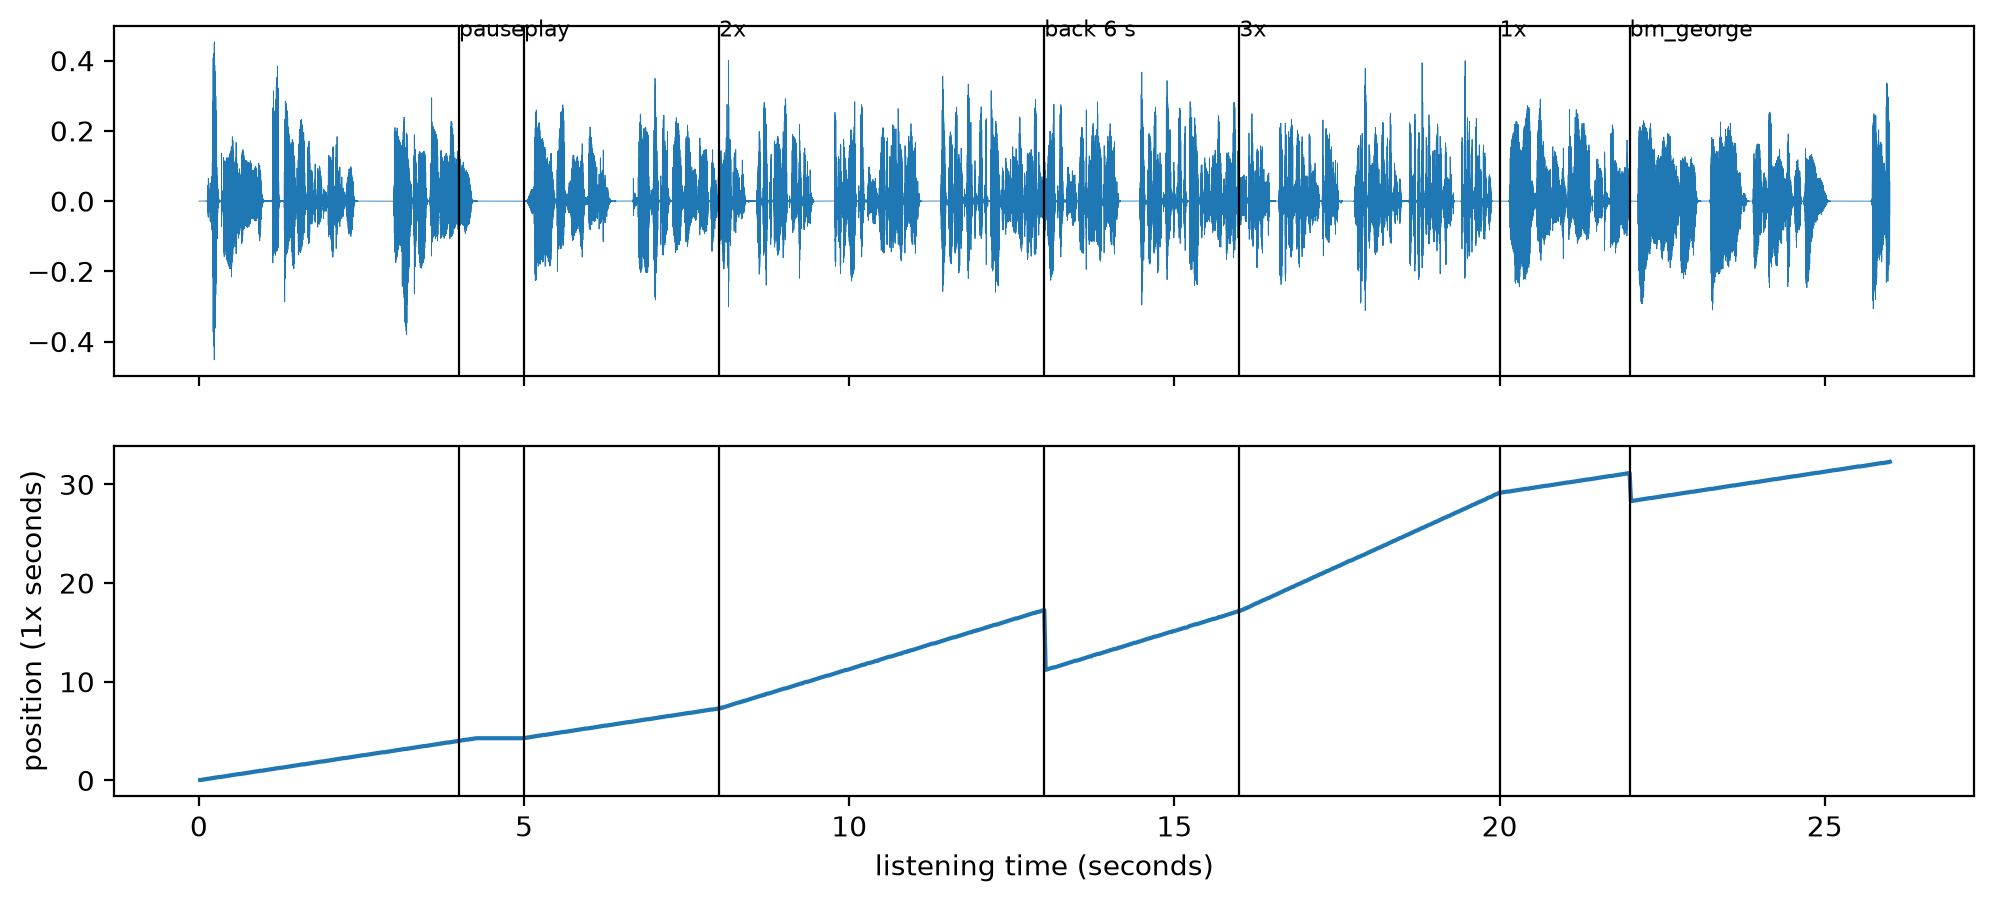

In [ ]:
player = Player(article)
script = {
    0: player.play,
    4: player.pause,
    5: player.play,
    8: lambda: player.set_speed(2),
    13: lambda: player.skip(-6),
    16: lambda: player.set_speed(3),
    20: lambda: player.set_speed(1),
    22: lambda: player.set_voice("bm_george"),
}
recording, heard, positions = session(player, script, 26)
times = np.arange(1, len(positions) + 1) * 480 / SR


def rate(start, end):
    "1x seconds of text per second of listening."
    return (np.interp(end, times, positions) - np.interp(start, times, positions)) / (end - start)


fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
axes[0].plot(np.arange(len(recording)) / SR, recording, lw=0.3)
axes[1].plot(times, positions)
axes[1].set_ylabel("position (1x seconds)")
axes[1].set_xlabel("listening time (seconds)")
for at, label in [(4, "pause"), (5, "play"), (8, "2x"), (13, "back 6 s"), (16, "3x"), (20, "1x"), (22, "bm_george")]:
    for ax in axes:
        ax.axvline(at, color="k", lw=0.8)
    axes[0].text(at, recording.max(), label, fontsize=8, va="bottom")
plt.show()
test_close(rate(0.5, 3.5), 1, eps=0.05)
test_eq(rate(4.5, 5), 0)
test_close(rate(9, 12.9), 2, eps=0.1)
test_close(rate(16.5, 19.5), 3, eps=0.15)
assert [w for t, w in heard if t > 22.5], "the new voice should carry on reading"
Audio(recording, rate=SR)

## Speakers and buttons

`speakers` gives the sound card `pull`. `controls` puts buttons on it, with the current word in bold as it's spoken.
These cells make a noise, so `nbdev-test` skips them.

In [ ]:
#| export
@patch
def speakers(self: Player):
    "Play whatever `pull` returns on the default output device. Returns the stream; `.close()` it to stop."

    def callback(out, frames, time, status):
        out[:, 0] = self.pull(frames)

    stream = sd.OutputStream(samplerate=SR, channels=1, dtype="float32", blocksize=BLOCK, callback=callback)
    stream.start()
    return stream


VOICES = [
    f"{g}_{n}"
    for g, ns in {
        "af": "alloy aoede bella heart jessica kore nicole nova river sarah sky",
        "am": "adam echo eric fenrir liam michael onyx puck santa",
        "bf": "alice emma isabella lily",
        "bm": "daniel fable george lewis",
    }.items()
    for n in ns.split()
]


def controls(player):
    "Speakers, buttons and the text with the current word in bold, for `player`."
    from html import escape

    import ipywidgets as widgets

    text = widgets.HTML()

    def show(a, b):
        t = player.text
        text.value = f"{escape(t[max(0, a - 120) : a])}<b>{escape(t[a:b])}</b>{escape(t[b : b + 120])}"

    player.on_word = show
    stream = player.speakers()
    toggle = widgets.ToggleButton(description="Play")
    back, forward, stop = (widgets.Button(description=d) for d in ["« 15 s", "15 s »", "Stop"])
    voice = widgets.Dropdown(options=VOICES, value=player.voice, description="Voice")
    speed = widgets.Dropdown(options=[0.5, 0.75, 1, 1.25, 1.5, 2, 2.5, 3], value=player.speed, description="Speed")
    toggle.observe(lambda c: player.play() if c.new else player.pause(), "value")
    back.on_click(lambda _: player.skip(-15))
    forward.on_click(lambda _: player.skip(15))
    stop.on_click(lambda _: stream.close())
    voice.observe(lambda c: player.set_voice(c.new), "value")
    speed.observe(lambda c: player.set_speed(c.new), "value")
    return widgets.VBox([widgets.HBox([back, toggle, forward, stop]), widgets.HBox([voice, speed]), text])

In [ ]:
#| eval: false
controls(Player(article))

## Summary

| Control | How |
|---|---|
| Play | sentence by sentence, rendered a few ahead |
| Follow the words | each word announced, with its place in the text, as it's fed to Sonic |
| Pause | at the end of the current word, then Sonic drains |
| Seek and skip | to the start of a word, in 1x time |
| Speed | Sonic's, from the next block |
| Voice | the current sentence again, in the new voice |

Words are announced slightly before they're heard (Sonic's buffer and the sound card's), and positions in sentences
not yet rendered are estimates. Next: making the decoder fast.